# ¿Sobrevive un clasificador difuso-evolutivo a la llegada de la IA al kernel de Linux?

Proyecto final de Inteligencia Computacional (MCIC, Universidad Distrital), Juan Felipe Rodríguez Galindo.

Este cuaderno reproduce, desde una sesión limpia, la evaluación final del artículo: parte de la tabla de commits ya minada y anonimizada, verifica la huella de la partición de prueba, entrena los cinco modelos con la configuración congelada en la etapa E4 y los evalúa una sola vez en los commits de 2026.

- **Datos:** un commit por fila (2019–2026), autor reemplazado por un identificador con sal. La minería del clon del kernel (`minar_kernel.py`) va aparte porque toma 30–60 min y 6,5 GB.
- **Etiqueta:** el commit es *riesgoso* si un `Fixes:` posterior lo cita en ≤ 90 días; los commits sin 90 días de observación (censurados) se excluyen.
- **Modo:** `RAPIDO` entrena una semilla por modelo (la semilla de referencia, ~20 min en Colab); `COMPLETO` entrena las cinco semillas (~1,5 h).

In [1]:
MODO = "RAPIDO"        # o "COMPLETO"
URL_DATOS = "PENDIENTE"
ARCHIVO = "juan-rodriguez-20261595004-kernel-commits-2019-2026.parquet"
SEMILLA_BOOTSTRAP = 1
N_BOOT = 1000

In [2]:
import os, sys, platform, urllib.request
import numpy as np, pandas as pd, sklearn, matplotlib
import matplotlib.pyplot as plt
if not os.path.exists(ARCHIVO):
    urllib.request.urlretrieve(URL_DATOS, ARCHIVO)
print('Python', platform.python_version(), '| numpy', np.__version__, '| pandas',
      pd.__version__, '| scikit-learn', sklearn.__version__)
print('tabla:', ARCHIVO, round(os.path.getsize(ARCHIVO) / 2**20, 1), 'MB')

Python 3.13.15 | numpy 2.5.4 | pandas 3.1.1 | scikit-learn 1.9.1
tabla: juan-rodriguez-20261595004-kernel-commits-2019-2026.parquet 29.9 MB


## 1. Piezas comunes

Copiadas literalmente de `src/comun.py`: partición temporal con hueco de 90 días, huella de la prueba, modelos de referencia y métricas.

In [3]:
import hashlib, json, time
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, matthews_corrcoef, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

INICIO = '2019-01-01'
HUECO_DIAS = 90
PRUEBA = ('2026-01-01', '2026-08-01')
SEMILLAS = [11, 23, 37, 41, 53]
VARIABLES = ['lineas_add', 'lineas_del', 'n_archivos', 'n_binarios', 'n_dirs_raiz', 'n_subsistemas', 'n_reviewed', 'n_acked', 'n_tested', 'n_reported', 'n_signed', 'n_codev', 'n_link', 'cc_stable', 'es_fix', 'asunto_fix', 'len_asunto', 'exp_autor', 'dias_desde_primer_commit', 'exp_autor_subsistema', 'hora_utc', 'dia_semana']
VARIABLES_DIFUSO = ['lineas_add', 'lineas_del', 'n_archivos', 'n_subsistemas', 'n_reviewed', 'n_signed', 'es_fix', 'cc_stable', 'exp_autor', 'exp_autor_subsistema']

def _ts(x):
    t = pd.Timestamp(x)
    return t.tz_localize("UTC") if t.tzinfo is None else t.tz_convert("UTC")


def tramo(df, a, b):
    f = df["fecha"]
    return df[(f >= _ts(a)) & (f < _ts(b))]


def particion(df, inicio_eval, ventana="creciente"):
    """Entrenamiento con hueco de 90 días antes de inicio_eval.

    ventana="creciente" (iteración 1): desde INICIO. ventana="deslizante_3a" (iteración 2):
    solo los ANIOS_DESLIZANTE años anteriores al fin del entrenamiento.
    """
    fin = _ts(inicio_eval) - pd.Timedelta(days=HUECO_DIAS)
    if ventana == "creciente":
        return tramo(df, INICIO, fin)
    if ventana == "deslizante_3a":
        return tramo(df, fin - pd.DateOffset(years=ANIOS_DESLIZANTE), fin)
    raise ValueError(ventana)


def huella_prueba(df):
    """SHA-256 de los hashes y etiquetas de la prueba: prueba que no cambió."""
    te = tramo(df, *PRUEBA)
    h = hashlib.sha256()
    for c, r in zip(te["hash"], te["riesgoso"]):
        h.update(f"{c}{r}".encode())
    return h.hexdigest(), int(len(te))


def _log1p(z):
    return np.log1p(np.clip(z, 0, None))


def modelo(nombre, semilla=0, variables=None, **hp):
    """variables: lista de variables del difuso (por omisión VARIABLES_DIFUSO, iteración 1)."""
    variables = VARIABLES_DIFUSO if variables is None else list(variables)
    if nombre == "mayoritaria":
        return Mayoritaria()
    if nombre == "logistica":
        return make_pipeline(FunctionTransformer(_log1p), StandardScaler(),
                             LogisticRegression(C=hp.get("C", 1.0), max_iter=3000))
    if nombre == "gboosting":
        return HistGradientBoostingClassifier(
            learning_rate=hp.get("learning_rate", 0.1), max_leaf_nodes=hp.get("max_leaf_nodes", 31),
            max_iter=hp.get("max_iter", 200), random_state=semilla)
    if nombre == "difuso_evolutivo":
        return ClasificadorDifuso(variables, evolutivo=True, semilla=semilla, **hp)
    if nombre == "difuso_sin_evolucion":
        return ClasificadorDifuso(variables, evolutivo=False, semilla=semilla, **hp)
    raise ValueError(nombre)


def columnas(nombre, variables=None):
    if nombre.startswith("difuso"):
        return VARIABLES_DIFUSO if variables is None else list(variables)
    return VARIABLES


class Mayoritaria:
    """Referencia trivial: siempre 'no riesgoso'. Puntaje constante = prevalencia."""
    def fit(self, X, y):
        self.p_ = float(np.mean(y))
        return self

    def predict_proba(self, X):
        n = len(X)
        return np.column_stack([np.full(n, 1 - self.p_), np.full(n, self.p_)])


def n_parametros(nombre, m):
    if nombre == "mayoritaria":
        return 1
    if nombre == "logistica":
        lr = m[-1]
        return int(lr.coef_.size + lr.intercept_.size)
    if nombre == "gboosting":
        return int(sum(p.get_n_leaf_nodes() * 2 - 1 for it in m._predictors for p in it))
    return int(m.n_parametros())


def ajustar(nombre, tr, semilla=0, variables=None, **hp):
    m = modelo(nombre, semilla, variables=variables, **hp)
    X = tr[columnas(nombre, variables)].to_numpy(float)
    t0 = time.time()
    m.fit(X, tr["riesgoso"].to_numpy())
    return m, time.time() - t0


def predecir(nombre, m, te):
    t0 = time.time()
    # el difuso guarda sus variables; así se predice con las mismas con que se ajustó
    cols = list(m.variables) if nombre.startswith("difuso") else columnas(nombre)
    p = m.predict_proba(te[cols].to_numpy(float))[:, 1]
    return p, time.time() - t0


# ------------------------------------------------------------------ métricas
def umbral_mcc(y, p):
    """Umbral que maximiza el MCC (se elige en validación y se aplica en prueba)."""
    cand = np.unique(np.quantile(p, np.linspace(0.5, 0.995, 120)))
    mcc = [matthews_corrcoef(y, p >= u) for u in cand]
    return float(cand[int(np.argmax(mcc))])


def metricas(y, p, umbral=None):
    y = np.asarray(y)
    r = {"n": int(len(y)), "prevalencia": float(y.mean()),
         "auc_pr": float(average_precision_score(y, p)) if y.sum() else float("nan"),
         "auc_roc": float(roc_auc_score(y, p)) if 0 < y.sum() < len(y) else float("nan")}
    r["auc_pr_sobre_prev"] = r["auc_pr"] / r["prevalencia"]
    if umbral is not None:
        yp = p >= umbral
        tp, fn = int((yp & (y == 1)).sum()), int((~yp & (y == 1)).sum())
        tn, fp = int((~yp & (y == 0)).sum()), int((yp & (y == 0)).sum())
        r.update({"umbral": umbral, "mcc": float(matthews_corrcoef(y, yp)),
                  "sensibilidad": tp / max(tp + fn, 1), "especificidad": tn / max(tn + fp, 1),
                  "marcados": float(yp.mean()), "tp": tp, "fp": fp, "tn": tn, "fn": fn})
    return r


def bootstrap_ic(y, p, f=average_precision_score, n=N_BOOT, semilla=0):
    rng = np.random.default_rng(semilla)
    y, p = np.asarray(y), np.asarray(p)
    vals = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if y[i].sum():
            vals.append(f(y[i], p[i]))
    return [float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))]


## 2. Clasificador difuso-evolutivo

Copia literal de `src/difuso.py`. Tres términos de Ruspini por variable sobre la escala de cuantiles, reglas con t-norma producto y O probabilístico; un algoritmo genético tipo Pittsburgh ajusta a la vez los vértices y la base de reglas. La *variante sin evolución* es la solución voraz con la que se siembra la población, así que la diferencia entre ambas mide el aporte de la evolución.

In [4]:
from dataclasses import dataclass, field
from itertools import combinations, product

import numpy as np
from sklearn.metrics import average_precision_score
from sklearn.preprocessing import QuantileTransformer

TERMINOS = ("bajo", "medio", "alto")
MAX_ANT = 3


# ------------------------------------------------------------------ pertenencias
def pertenencias(z, vert):
    """z: (n, k) en [0, 1]; vert: (k, 3) vértices a<b<c. Devuelve (n, k, 3)."""
    a, b, c = vert[:, 0], vert[:, 1], vert[:, 2]
    eps = 1e-9
    bajo = np.clip((b - z) / (b - a + eps), 0, 1)
    alto = np.clip((z - b) / (c - b + eps), 0, 1)
    medio = np.clip(np.minimum((z - a) / (b - a + eps), (c - z) / (c - b + eps)), 0, 1)
    return np.stack([bajo, medio, alto], axis=2)


def puntaje(mu, reglas):
    """mu: (n, k, 3). reglas: lista de (antecedentes [(var, term)], peso)."""
    n = mu.shape[0]
    no_riesgo = np.ones(n)
    for ants, w in reglas:
        act = np.ones(n)
        for v, t in ants:
            act = act * mu[:, v, t]
        no_riesgo *= 1 - w * act
    return 1 - no_riesgo


def ordenar_vertices(v):
    v = np.sort(np.clip(v, 0.0, 1.0), axis=1)
    v[:, 1] = np.maximum(v[:, 1], v[:, 0] + 0.02)     # separaciones mínimas
    v[:, 2] = np.maximum(v[:, 2], v[:, 1] + 0.02)
    return np.clip(v, 0.0, 1.0)


# ------------------------------------------------------------------ clasificador
@dataclass
class ClasificadorDifuso:
    variables: list
    evolutivo: bool = True
    n_reglas: int = 15             # máximo de reglas
    poblacion: int = 60
    generaciones: int = 80
    prob_mutacion: float = 0.15
    prob_cruce: float = 0.9
    torneo: int = 3
    elitismo: int = 2
    lambda_complejidad: float = 0.002
    muestra_aptitud: int = 80_000  # filas para evaluar la aptitud (prevalencia natural)
    soporte_min: float = 0.002     # solo variante sin evolución
    semilla: int = 0
    historia_: list = field(default_factory=list, init=False)

    # -------------------------------------------------------------- utilidades
    def _transformar(self, X):
        return self.qt_.transform(X)

    def _decodificar(self, ind):
        k = len(self.variables)
        vert = ordenar_vertices(ind["vert"].reshape(k, 3))
        reglas = []
        for r in range(self.n_reglas):
            if not ind["activa"][r]:
                continue
            ants = [(int(v), int(t)) for v, t in zip(ind["var"][r], ind["term"][r]) if v >= 0]
            vistos, limpios = set(), []
            for v, t in ants:                      # una variable a lo sumo una vez por regla
                if v not in vistos:
                    vistos.add(v)
                    limpios.append((v, t))
            if limpios:
                reglas.append((limpios, float(ind["peso"][r])))
        return vert, reglas

    def _aptitud(self, ind, z, y):
        vert, reglas = self._decodificar(ind)
        if not reglas:
            return 0.0, 0
        s = puntaje(pertenencias(z, vert), reglas)
        n_ant = sum(len(a) for a, _ in reglas)
        return average_precision_score(y, s) - self.lambda_complejidad * n_ant, n_ant

    # -------------------------------------------------------------- operadores GA
    def _aleatorio(self, rng):
        k, R = len(self.variables), self.n_reglas
        var = rng.integers(-1, k, size=(R, MAX_ANT))
        var[:, 0] = rng.integers(0, k, size=R)            # al menos un antecedente
        return {"vert": ordenar_vertices(np.tile([0.2, 0.5, 0.8], (k, 1))
                                         + rng.normal(0, 0.08, (k, 3))).ravel(),
                "activa": rng.random(R) < 0.6,
                "var": var, "term": rng.integers(0, 3, size=(R, MAX_ANT)),
                "peso": rng.random(R)}

    def _cruce(self, p1, p2, rng):
        h = {}
        for g in ("vert", "activa", "peso"):               # uniforme gen a gen
            m = rng.random(p1[g].shape) < 0.5
            h[g] = np.where(m, p1[g], p2[g])
        # antecedentes y términos se heredan por regla completa, juntos
        m = rng.random(self.n_reglas) < 0.5
        h["var"] = np.where(m[:, None], p1["var"], p2["var"])
        h["term"] = np.where(m[:, None], p1["term"], p2["term"])
        if rng.random() < 0.5:                             # la regla r hereda también su peso
            h["activa"] = np.where(m, p1["activa"], p2["activa"])
            h["peso"] = np.where(m, p1["peso"], p2["peso"])
        return h

    def _mutar(self, ind, rng):
        k, pm = len(self.variables), self.prob_mutacion
        ind = {g: v.copy() for g, v in ind.items()}
        m = rng.random(ind["vert"].shape) < pm
        ind["vert"][m] += rng.normal(0, 0.06, m.sum())
        m = rng.random(self.n_reglas) < pm
        ind["activa"][m] = ~ind["activa"][m]
        m = rng.random(ind["var"].shape) < pm
        ind["var"][m] = rng.integers(-1, k, m.sum())
        ind["var"][:, 0] = np.where(ind["var"][:, 0] < 0, rng.integers(0, k, self.n_reglas),
                                    ind["var"][:, 0])
        m = rng.random(ind["term"].shape) < pm
        ind["term"][m] = rng.integers(0, 3, m.sum())
        m = rng.random(self.n_reglas) < pm
        ind["peso"][m] = np.clip(ind["peso"][m] + rng.normal(0, 0.15, m.sum()), 0.01, 1)
        ind["vert"] = ordenar_vertices(ind["vert"].reshape(k, 3)).ravel()
        return ind

    # -------------------------------------------------------------- ajuste
    def fit(self, X, y):
        rng = np.random.default_rng(self.semilla)
        X = np.asarray(X, float)
        y = np.asarray(y).astype(int)
        self.qt_ = QuantileTransformer(n_quantiles=1000, subsample=200_000,
                                       random_state=self.semilla).fit(X)
        z = self._transformar(X)
        if len(z) > self.muestra_aptitud:
            i = rng.choice(len(z), self.muestra_aptitud, replace=False)
            z, y = z[i], y[i]
        if self.evolutivo:
            self._fit_evolutivo(z, y, rng)
        else:
            self._fit_voraz(z, y)
        return self

    def _codificar(self, vert, reglas):
        """Base de reglas -> individuo (para sembrar el GA con la solución voraz)."""
        R = self.n_reglas
        var = np.full((R, MAX_ANT), -1)
        term = np.zeros((R, MAX_ANT), int)
        activa = np.zeros(R, bool)
        peso = np.full(R, 0.5)
        for r, (ants, w) in enumerate(reglas[:R]):
            activa[r], peso[r] = True, w
            for j, (v, t) in enumerate(ants[:MAX_ANT]):
                var[r, j], term[r, j] = v, t
        var[:, 0] = np.where(var[:, 0] < 0, 0, var[:, 0])
        return {"vert": vert.ravel().copy(), "activa": activa, "var": var, "term": term,
                "peso": peso}

    def _fit_evolutivo(self, z, y, rng):
        # Siembra: la solución de la variante sin evolución y mutaciones suyas; el resto al azar.
        # Así la variante sin evolución aísla exactamente el aporte de la evolución.
        self._fit_voraz(z, y)
        semilla_ind = self._codificar(self.vert_, self.reglas_)
        n_sembrados = self.poblacion // 4
        pob = [semilla_ind] + [self._mutar(semilla_ind, rng) for _ in range(n_sembrados - 1)]
        pob += [self._aleatorio(rng) for _ in range(self.poblacion - n_sembrados)]
        apt = np.array([self._aptitud(p, z, y)[0] for p in pob])
        for gen in range(self.generaciones):
            orden = np.argsort(-apt)
            nueva = [pob[i] for i in orden[: self.elitismo]]
            while len(nueva) < self.poblacion:
                def elegir():
                    c = rng.choice(self.poblacion, self.torneo, replace=False)
                    return pob[c[np.argmax(apt[c])]]
                p1, p2 = elegir(), elegir()
                h = self._cruce(p1, p2, rng) if rng.random() < self.prob_cruce else \
                    {g: v.copy() for g, v in p1.items()}
                nueva.append(self._mutar(h, rng))
            pob = nueva
            apt = np.array([self._aptitud(p, z, y)[0] for p in pob])
            self.historia_.append((gen, float(apt.max()), float(np.median(apt))))
        mejor = pob[int(np.argmax(apt))]
        self.vert_, self.reglas_ = self._decodificar(mejor)

    def _fit_voraz(self, z, y):
        k = len(self.variables)
        self.vert_ = np.tile([0.2, 0.5, 0.8], (k, 1)).astype(float)
        mu = pertenencias(z, self.vert_)
        candidatas = []
        for n_ant in (1, 2):
            for vs in combinations(range(k), n_ant):
                for ts in product(range(3), repeat=n_ant):
                    act = np.prod([mu[:, v, t] for v, t in zip(vs, ts)], axis=0)
                    sop = act.mean()
                    if sop < self.soporte_min:
                        continue
                    conf = (act * y).sum() / (act.sum() + 1e-12)
                    candidatas.append((conf, list(zip(vs, ts))))
        candidatas.sort(key=lambda c: -c[0])
        # voraz: añadir reglas mientras mejoren el AUC-PR de entrenamiento
        reglas, mejor = [], 0.0
        for conf, ants in candidatas[: 200]:
            if len(reglas) >= self.n_reglas:
                break
            prueba = reglas + [(ants, float(conf))]
            ap = average_precision_score(y, puntaje(mu, prueba))
            if ap > mejor + 1e-4:
                reglas, mejor = prueba, ap
        self.reglas_ = reglas

    # -------------------------------------------------------------- uso
    def predict_proba(self, X):
        z = self._transformar(np.asarray(X, float))
        s = puntaje(pertenencias(z, self.vert_), self.reglas_)
        return np.column_stack([1 - s, s])

    def n_parametros(self):
        usados = {v for ants, _ in self.reglas_ for v, _ in ants}
        return 3 * len(usados) + sum(len(a) + 1 for a, _ in self.reglas_)

    def _z_columna(self, v, x):
        """Transformación por cuantiles de una sola variable (igual que QuantileTransformer:
        promedio de la interpolación ascendente y descendente, para manejar empates)."""
        q, ref = self.qt_.quantiles_[:, v], self.qt_.references_
        x = np.asarray(x, float)
        z = 0.5 * (np.interp(x, q, ref) - np.interp(-x, -q[::-1], -ref[::-1]))
        z = np.where(x <= q[0], ref[0], z)       # sklearn lleva los extremos exactos a 0 y 1
        return np.where(x >= q[-1], ref[-1], z)

    def corte(self, v, t, alfa=0.5):
        """Valores originales de la variable v donde el término t tiene pertenencia >= alfa."""
        x = np.unique(self.qt_.quantiles_[:, v])
        mu = pertenencias(self._z_columna(v, x)[:, None], self.vert_[[v]])[:, 0, t]
        return x[mu >= alfa]

    def reglas_legibles(self, alfa=0.5):
        """Reglas en unidades originales: cada término se resume con su corte alfa
        (valores con pertenencia >= alfa), evaluado sobre los cuantiles de entrenamiento."""
        def fmt(x):
            return f"{x:.0f}" if float(x).is_integer() else f"{x:.3g}"

        lineas = []
        for i, (ants, w) in enumerate(sorted(self.reglas_, key=lambda r: -r[1]), 1):
            partes = []
            for v, t in ants:
                x = self.corte(v, t, alfa)
                todos = np.unique(self.qt_.quantiles_[:, v])
                if len(x) == 0:
                    rango = "ningún valor"
                elif len(x) == 1:
                    rango = f"= {fmt(x[0])}"
                elif x[0] == todos[0]:
                    rango = f"<= {fmt(x[-1])}"
                elif x[-1] == todos[-1]:
                    rango = f">= {fmt(x[0])}"
                else:
                    rango = f"entre {fmt(x[0])} y {fmt(x[-1])}"
                partes.append(f"{self.variables[v]} es {TERMINOS[t]} ({rango})")
            lineas.append(f"R{i} (peso {w:.2f}): SI " + " Y ".join(partes) + " ENTONCES riesgoso")
        return lineas


## 3. Datos y verificaciones

Se cargan los commits no censurados y se comprueba que la partición de prueba es exactamente la que se congeló antes de evaluar.

In [5]:
df = pd.read_parquet(ARCHIVO)
df = df[~df['censurado']].sort_values('t_commit', kind='stable').reset_index(drop=True)
CONFIG = json.loads("{\"congelada_en\": \"2026-11-07T23:41:00\", \"difuso_evolutivo\": {\"config\": {\"generaciones\": 140, \"lambda_complejidad\": 0.0005, \"n_reglas\": 15, \"poblacion\": 80, \"prob_cruce\": 0.9, \"prob_mutacion\": 0.05}, \"semillas\": [11, 23, 37, 41, 53], \"umbral_mcc_por_semilla\": {\"11\": 0.5389729767519064, \"23\": 0.7679513198229324, \"37\": 0.8078425756590831, \"41\": 0.542489455019369, \"53\": 0.811495551953093}, \"semilla_para_mcnemar\": 11, \"criterio_semilla\": \"mediana del AUC-PR medio de validaci\u00f3n\"}, \"difuso_sin_evolucion\": {\"config\": {\"n_reglas\": 15}, \"umbral_mcc\": 0.3240095751976977}, \"referencias\": {\"mayoritaria\": {\"config\": {}, \"umbral_mcc\": 1.0}, \"logistica\": {\"config\": {\"C\": 0.01}, \"umbral_mcc\": 0.08357242708285184}, \"gboosting\": {\"config\": {\"learning_rate\": 0.05, \"max_leaf_nodes\": 15}, \"umbral_mcc\": 0.10336941463793838}}, \"mejor_referencia_clasica\": \"gboosting\", \"entrenamiento_final\": [\"2019-01-01\", \"2026-01-01 menos 90 d\u00edas\"], \"prueba\": {\"tramo\": [\"2026-01-01\", \"2026-08-01\"], \"n\": 54373, \"sha256\": \"11e7039f3cc279120025ccc8959a207990a4a75f6546ae4c330605c831a19b63\"}}")
huella, n_prueba = huella_prueba(df)
assert huella == CONFIG['prueba']['sha256'] and n_prueba == CONFIG['prueba']['n'], 'la prueba cambió'
tr, te = particion(df, PRUEBA[0]), tramo(df, *PRUEBA)
y = te['riesgoso'].to_numpy()
print(f'commits no censurados: {len(df):,}')
print(f'entrenamiento final: {len(tr):,} ({tr.fecha.min():%Y-%m-%d} a {tr.fecha.max():%Y-%m-%d}),'
      f' prevalencia {tr.riesgoso.mean():.4f}')
print(f'prueba 2026: {len(te):,}, prevalencia {y.mean():.4f}; huella verificada {huella[:16]}…')
print('autores distintos (anonimizados):', df['autor'].nunique())

commits no censurados: 615,793
entrenamiento final: 541,269 (2019-01-01 a 2025-10-02), prevalencia 0.0425
prueba 2026: 54,373, prevalencia 0.0346; huella verificada 11e7039f3cc27912…
autores distintos (anonimizados): 20632


In [6]:
anual = df.assign(anio=df.fecha.dt.year).groupby('anio').agg(
    commits=('riesgoso', 'size'), prevalencia=('riesgoso', 'mean'),
    con_assisted_by=('assisted_by', 'sum'), lineas_add_mediana=('lineas_add', 'median'))
anual

,commits,prevalencia,con_assisted_by,lineas_add_mediana
anio,,,,
2019,76493,0.042684,0,7.0
2020,83651,0.044124,0,7.0
2021,79671,0.044659,0,6.0
2022,79192,0.043237,0,7.0
2023,84780,0.038865,0,7.0
2024,76501,0.041385,0,7.0
2025,78150,0.042687,2,8.0
2026,57355,0.033946,2309,8.0


## 4. Entrenamiento final y evaluación única en 2026

Configuración congelada en E4 (búsqueda aleatoria, sensibilidad y semillas solo sobre 2023–2025). Umbral de MCC fijado en la ventana de validación 2025.

In [7]:
plan = [('mayoritaria', CONFIG['referencias']['mayoritaria'], [SEMILLAS[0]]),
        ('logistica', CONFIG['referencias']['logistica'], [SEMILLAS[0]]),
        ('gboosting', CONFIG['referencias']['gboosting'], SEMILLAS),
        ('difuso_sin_evolucion', CONFIG['difuso_sin_evolucion'], [SEMILLAS[0]]),
        ('difuso_evolutivo', CONFIG['difuso_evolutivo'], SEMILLAS)]
s_ref = CONFIG['difuso_evolutivo']['semilla_para_mcnemar']
preds, filas, modelos = {}, [], {}
for nombre, c, semillas in plan:
    if MODO == 'RAPIDO':
        semillas = [s_ref if nombre == 'difuso_evolutivo' else semillas[0]]
    for s in semillas:
        m, t_fit = ajustar(nombre, tr, semilla=s, **c['config'])
        p, _ = predecir(nombre, m, te)
        u = c['umbral_mcc_por_semilla'][str(s)] if 'umbral_mcc_por_semilla' in c else c['umbral_mcc']
        r = metricas(y, p, u)
        preds[nombre, s], modelos[nombre, s] = p, m
        filas.append({'modelo': nombre, 'semilla': s, 'auc_pr': r['auc_pr'],
                      'auc_roc': r['auc_roc'], 'mcc': r['mcc'], 'sensibilidad': r['sensibilidad'],
                      'especificidad': r['especificidad'], 'n_parametros': n_parametros(nombre, m),
                      'entrenamiento_s': round(t_fit, 1)})
        print(f'{nombre:22s} semilla {s}: AUC-PR {r["auc_pr"]:.4f}  ({t_fit:.0f} s)', flush=True)
tabla = pd.DataFrame(filas)
tabla.round(4)

mayoritaria            semilla 11: AUC-PR 0.0346  (0 s)


logistica              semilla 11: AUC-PR 0.1274  (0 s)


gboosting              semilla 11: AUC-PR 0.1321  (5 s)


difuso_sin_evolucion   semilla 11: AUC-PR 0.0901  (1 s)


difuso_evolutivo       semilla 11: AUC-PR 0.1172  (223 s)


,modelo,semilla,auc_pr,auc_roc,mcc,sensibilidad,especificidad,n_parametros,entrenamiento_s
0,mayoritaria,11,0.0346,0.5000,0.0000,0.0000,1.0000,1,0.0
1,logistica,11,0.1274,0.7653,0.1794,0.4330,0.8886,23,0.3
2,gboosting,11,0.1321,0.7689,0.1873,0.3990,0.9097,5626,4.7
3,difuso_sin_evolucion,11,0.0901,0.7405,0.1530,0.5654,0.7852,71,1.1
4,difuso_evolutivo,11,0.1172,0.7604,0.1656,0.5138,0.8333,25,223.0


### Comparación con las cifras del artículo

Cada entrenamiento es determinista por semilla, así que el AUC-PR debe coincidir con el que reporta el artículo.

In [8]:
ESPERADO = {
 "mayoritaria": {
  "11": 0.034612767366156
 },
 "logistica": {
  "11": 0.12743577291166303
 },
 "gboosting": {
  "11": 0.13209360519958988,
  "23": 0.13093283823730284,
  "37": 0.1318134546565493,
  "41": 0.13306778578398748,
  "53": 0.13210216154246643
 },
 "difuso_sin_evolucion": {
  "11": 0.09013094356659936
 },
 "difuso_evolutivo": {
  "11": 0.1171784369933376,
  "23": 0.1207211438721065,
  "37": 0.11924113992604013,
  "41": 0.12448227342983144,
  "53": 0.11961388149219862
 }
}
tabla['esperado'] = [ESPERADO[m][str(s)] for m, s in zip(tabla.modelo, tabla.semilla)]
tabla['diferencia'] = (tabla.auc_pr - tabla.esperado).abs()
print('máxima diferencia con el artículo:', tabla.diferencia.max())
tabla[['modelo', 'semilla', 'auc_pr', 'esperado', 'diferencia']]

máxima diferencia con el artículo: 0.0


,modelo,semilla,auc_pr,esperado,diferencia
0,mayoritaria,11,0.034613,0.034613,0.0
1,logistica,11,0.127436,0.127436,0.0
2,gboosting,11,0.132094,0.132094,0.0
3,difuso_sin_evolucion,11,0.090131,0.090131,0.0
4,difuso_evolutivo,11,0.117178,0.117178,0.0


## 5. Criterio de éxito, intervalos y McNemar

Fijado antes de evaluar (Entrega 1): **C1** AUC-PR del difuso-evolutivo ≥ 0,95 del mejor clásico (R); **C2** su caída relativa de validación a prueba menor que la de R; **C3** su IC 95 % excluye la prevalencia y McNemar contra R.

In [9]:
from scipy.stats import chi2
def mcnemar(y, a, b):
    ca, cb = a == y, b == y
    n01, n10 = int((ca & ~cb).sum()), int((~ca & cb).sum())
    est = (abs(n01 - n10) - 1) ** 2 / max(n01 + n10, 1)
    return n01, n10, float(chi2.sf(est, 1))

R = CONFIG['mejor_referencia_clasica']
media = tabla.groupby('modelo').auc_pr.mean()
VAL = {"mayoritaria": 0.040979172822732446, "logistica": 0.14855469462346227, "gboosting": 0.15777654645088665, "difuso_sin_evolucion": 0.12058815837465786, "difuso_evolutivo": 0.14945014136947848}  # AUC-PR medio de validación (E3/E4)
caida = {m: (VAL[m] - media[m]) / VAL[m] for m in media.index}
ic = {m: bootstrap_ic(y, preds[m, (s_ref if m == 'difuso_evolutivo' else tabla[tabla.modelo == m].semilla.iloc[0])],
                      n=N_BOOT, semilla=SEMILLA_BOOTSTRAP) for m in media.index}
u_fe = CONFIG['difuso_evolutivo']['umbral_mcc_por_semilla'][str(s_ref)]
b_fe = preds['difuso_evolutivo', s_ref] >= u_fe
s_r = tabla[tabla.modelo == R].semilla.iloc[0]
n01, n10, p_mc = mcnemar(y, b_fe, preds[R, s_r] >= CONFIG['referencias'][R]['umbral_mcc'])
c1 = media['difuso_evolutivo'] / media[R]
print(f'R = {R}')
if MODO == 'RAPIDO':
    print('Modo RAPIDO: una semilla por modelo. El artículo usa la media de las 5 semillas del '
          'difuso-evolutivo y del gradient boosting (C1 = 0,911; caída 19,5 %); con MODO = "COMPLETO" '
          'este cuaderno las reproduce.')
print(f'C1: {c1:.3f} del AUC-PR de R (meta 0,95) ->', 'cumple' if c1 >= 0.95 else 'NO cumple')
print(f'C2: caída FE {caida["difuso_evolutivo"]:.3f} vs R {caida[R]:.3f} ->',
      'cumple' if caida['difuso_evolutivo'] < caida[R] else 'NO cumple')
print(f'C3 (primera parte): IC95 FE {np.round(ic["difuso_evolutivo"], 4)} vs prevalencia {y.mean():.4f} ->',
      'cumple' if ic['difuso_evolutivo'][0] > y.mean() else 'NO cumple')
print(f'C3 (segunda parte): McNemar FE vs {R}: FE acierta y R falla {n01}, al revés {n10}, p = {p_mc:.3g} ->',
      'significativo a favor de FE' if p_mc < 0.05 and n01 > n10 else
      ('significativo a favor de R: no cumple' if p_mc < 0.05 else 'no significativo: no cumple'))
pd.DataFrame({'AUC-PR prueba': media, 'IC95 inf': {m: v[0] for m, v in ic.items()},
              'IC95 sup': {m: v[1] for m, v in ic.items()}, 'AUC-PR validación': VAL,
              'caída relativa': caida}).round(4)

R = gboosting
Modo RAPIDO: una semilla por modelo. El artículo usa la media de las 5 semillas del difuso-evolutivo y del gradient boosting (C1 = 0,911; caída 19,5 %); con MODO = "COMPLETO" este cuaderno las reproduce.
C1: 0.887 del AUC-PR de R (meta 0,95) -> NO cumple
C2: caída FE 0.216 vs R 0.163 -> NO cumple
C3 (primera parte): IC95 FE [0.1075 0.1281] vs prevalencia 0.0346 -> cumple
C3 (segunda parte): McNemar FE vs gboosting: FE acierta y R falla 584, al revés 4379, p = 0 -> significativo a favor de R: no cumple


,AUC-PR prueba,IC95 inf,IC95 sup,AUC-PR validación,caída relativa
difuso_evolutivo,0.1172,0.1075,0.1281,0.1495,0.2159
difuso_sin_evolucion,0.0901,0.0833,0.0981,0.1206,0.2526
gboosting,0.1321,0.1208,0.1455,0.1578,0.1628
logistica,0.1274,0.1170,0.1399,0.1486,0.1422
mayoritaria,0.0346,0.0331,0.0361,0.0410,0.1554


## 6. Las reglas aprendidas

Base de reglas del difuso-evolutivo con la semilla de referencia, con los vértices traducidos a unidades originales.

In [10]:
print('\n'.join(modelos['difuso_evolutivo', s_ref].reglas_legibles()))

R1 (peso 0.62): SI lineas_add es alto (>= 16) ENTONCES riesgoso
R2 (peso 0.29): SI lineas_add es alto (>= 16) Y n_archivos es alto (>= 2) ENTONCES riesgoso
R3 (peso 0.21): SI n_subsistemas es medio (= 1) Y lineas_del es bajo (= 0) ENTONCES riesgoso
R4 (peso 0.13): SI n_subsistemas es alto (>= 2) Y lineas_del es medio (entre 1 y 4) ENTONCES riesgoso
R5 (peso 0.12): SI n_subsistemas es alto (>= 2) ENTONCES riesgoso


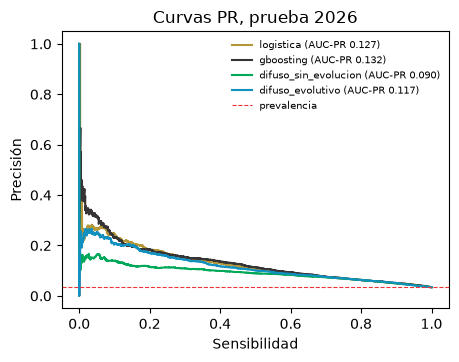

In [11]:
from sklearn.metrics import precision_recall_curve
colores = {'logistica': '#B49739', 'gboosting': '#373435',
           'difuso_sin_evolucion': '#00A859', 'difuso_evolutivo': '#1291C0'}
fig, ax = plt.subplots(figsize=(5, 3.6))
for m, col in colores.items():
    s = s_ref if m == 'difuso_evolutivo' else tabla[tabla.modelo == m].semilla.iloc[0]
    pr, rc, _ = precision_recall_curve(y, preds[m, s])
    ax.plot(rc, pr, color=col, label=f'{m} (AUC-PR {average_precision_score(y, preds[m, s]):.3f})')
ax.axhline(y.mean(), color='#ED3237', ls='--', lw=0.8, label='prevalencia')
ax.set_xlabel('Sensibilidad'); ax.set_ylabel('Precisión'); ax.set_title('Curvas PR, prueba 2026')
ax.legend(fontsize=7, frameon=False); plt.show()

## 7. Lectura

Las cifras de arriba son las del artículo: el criterio de éxito se evalúa tal como se fijó antes de mirar la prueba, sin ajustes posteriores. La búsqueda de hiperparámetros, la sensibilidad y las cinco semillas en validación están en `e4_busqueda.py` y en `registro_experimentos.csv`, entregados junto con este cuaderno.